In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
# pip install seaborn
import seaborn as sns

In [2]:
ENDERECO_DADOS = 'https://www.ispdados.rj.gov.br/Arquivos/BaseDPEvolucaoMensalCisp.csv'

# obter dados
try:
    print('Obtendo dados de ocorrências...')

    df_ocorrencias = pd.read_csv(ENDERECO_DADOS, sep=';', encoding='iso-8859-1')
    # print(df_ocorrencias.columns) # exibir o nome de todas as colunas

    print(df_ocorrencias.head())    
    # print('Dados obtidos com sucesso!')

except Exception as e:
    print('Erro ao obter dados: ', e)


Obtendo dados de ocorrências...
   cisp  mes   ano  mes_ano  aisp  risp           munic    mcirc   regiao  \
0     1    1  2003  2003m01     5     1  Rio de Janeiro  3304557  Capital   
1     4    1  2003  2003m01     5     1  Rio de Janeiro  3304557  Capital   
2     5    1  2003  2003m01     5     1  Rio de Janeiro  3304557  Capital   
3     6    1  2003  2003m01     1     1  Rio de Janeiro  3304557  Capital   
4     7    1  2003  2003m01     1     1  Rio de Janeiro  3304557  Capital   

   hom_doloso  ...  cmp  cmba  ameaca  pessoas_desaparecidas  \
0           0  ...  NaN   NaN      21                      2   
1           3  ...  NaN   NaN      15                      6   
2           3  ...  NaN   NaN      47                      2   
3           6  ...  NaN   NaN      26                      2   
4           4  ...  NaN   NaN      10                      1   

   encontro_cadaver  encontro_ossada  pol_militares_mortos_serv  \
0                 0                0                 

In [ ]:
# Delimitando as variáveis e a totalizando
try:
    print("inciando a delimitação das variáveis e a totalização...")    
    df_veiculos = df_ocorrencias[['cisp', 'roubo_veiculo', 'recuperacao_veiculos']]

    # Agrupar e totalizar os roubos e recuperações por CISP no pandas novo   
    df_total_veiculos = df_veiculos.groupby('cisp', as_index=False)[['roubo_veiculo', 'recuperacao_veiculos']].sum()
    print(df_total_veiculos)

except Exception as e:
    print("Erro ao delimitar o dataframe: ", e)

inciando a delimitação das variáveis e a totalização...
     cisp  roubo_veiculo  recuperacao_veiculos
0       1            583                   549
1       4           2230                  1939
2       5           1384                  1597
3       6           4708                  8250
4       7           2035                  1861
..    ...            ...                   ...
133   159            288                   353
134   165            504                   700
135   166            971                  1542
136   167            108                   417
137   168             66                   168

[138 rows x 3 columns]


In [4]:
# Calculando a Correlação.
try:
    print('Analisando dados...')

    # Excluir uma parte de valores extremos
    df_total_veiculos_cut = (
        df_total_veiculos[
            df_total_veiculos['roubo_veiculo'] < np.percentile(df_total_veiculos['roubo_veiculo'], 95)
        ]
    )
   
    df_total_veiculos_cut = (
        df_total_veiculos_cut[
            df_total_veiculos_cut['recuperacao_veiculos'] < np.percentile(df_total_veiculos_cut['recuperacao_veiculos'], 99)
        ]
    )

    # Transformando em Arrays
    array_roubo_veiculo = np.array(df_total_veiculos_cut['roubo_veiculo'])
    array_recuperacao_veiculos = np.array(df_total_veiculos_cut['recuperacao_veiculos'])

    # Calculando a correlação
    correlacao = np.corrcoef(array_roubo_veiculo, array_recuperacao_veiculos)[0, 1]
    print('Correlação: ', correlacao)

except Exception as e:
    print("Erro ao analisar dados: ", e)

Analisando dados...
Correlação:  0.9278465032428499


In [5]:
# Inciando modelo de Regressão Linear - Análise Preditiva
# Dividindo os dados em treino e teste
try:
    print("Iniciando a regressão linear...")
    # Instalar a biblioteca scikit-learn
    # SciKit-Learn é a principal biblioteca de Machine Learning para Python
    
    # pip install scikit-learn

    # Classe para dividir a distribuição dos dados em treino e teste
    from sklearn.model_selection import train_test_split

    # Dividir em treino e teste
    # Roubo de veículos (X): Variável independente - Utilizo para prever
    # Recuperação de veículos (Y): Variável dependente - a queremos prever
    X_train, X_test, y_train, y_test =(
        train_test_split(
            array_roubo_veiculo,        # Variável independente
            array_recuperacao_veiculos,  # Variável dependente  
            test_size=0.2, # tamanho do conjunto de teste, logo o treino terá 0.8
            random_state=42
        )
    )
    

except Exception as e:
    print("Erro ao separar treino e teste: ", e)

Iniciando a regressão linear...


In [6]:
# Aplicando o modelo de Regressão Linear
# Padronizando os dados de treino e teste
try:
    print("Padronizando os dados treino e testes...")

    # Importar a classe de padronização de dados
    from sklearn.preprocessing import StandardScaler

    # Criar o objeto responsável pela padronização
    scaler = StandardScaler()

    # Padronizar a variável (X) de treino (independente):
    # - O método fit calcula a média e o desvio padrão APENAS nos dados de treino.
    # - O método transform aplica a fórmula:
    #       "valor_padronizado = (valor - média_do_treino) / desvio_padrao_do_treino"
    # - O fit_transform faz as duas etapas ao mesmo tempo.
    # - O reshape(-1, 1) transforma o vetor em uma matriz de 1 coluna, com uma linha para cada CISP.
    X_train = scaler.fit_transform(X_train.reshape(-1, 1))


    # Aplica ao X_test a mesma transformação aprendida no X_train:
    # - Não calculamos nova média, nem novo desvio padrão.
    # - Reaproveitamos a média e o desvio padrão calculados nos dados de treino.
    # - Assim, treino e teste são transformados pela mesma regra.
    # - Por isso, usamos apenas o método transform e não o fit_transform.
    X_test = scaler.transform(X_test.reshape(-1, 1))

    print('Teste aplicado')

except Exception as e:
    print("Erro na padronização dos dados: ", e)

Padronizando os dados treino e testes...
Teste aplicado


In [7]:
# Aplicando o modelo de Regressão Linear
# Criando o modelo de regressão linear e treinando com os dados de treino
try:
    print("Criando o modelo de regressão linear...")

    # LinearRegression: É responsável por criar o modelo de regressão linear
    from sklearn.linear_model import LinearRegression

    # Cria o modelo linear: y = ax + b.
    # Neste momento, os valores de a (coeficiente) e b (intercepto)
    # ainda não foram calculados.
    modelo = LinearRegression()

    # Treina o modelo com os dados de treino.
    # O modelo encontra os valores de 'a' e 'b' que melhor relacionam os 
    # roubos de veículos (X) com as recuperações de veículos (y).
    modelo.fit(X_train, y_train)


    # Avalia o modelo com os dados de teste.
    # R² mede, o quanto da variação das recuperações o modelo consegue explicar.
    # O melhor valor é 1; o R² pode ser negativo, se o modelo for ruim.
    
    # Quanto mais perto de 1, melhor foi o aprendizado do modelo
        # Acima de 0.7 é um bom modelo.
        # Entre 0.5 e 0.7, é um modelo de qualidade moderada, recomenda-se verificar.
        # Abaixo de 0.5, é uma modelo de qualidade duvidosa
    r2_score = modelo.score(X_test, y_test)

    print("Avaliando o Modelo R²: ", r2_score)

except Exception as e:
    print("Erro ao realizar a regressão linear: ", e)

Criando o modelo de regressão linear...
Avaliando o Modelo R²:  0.9334558365233318


In [8]:
# Caculando a previsão de recuperação de veículos quando os roubos forem 5000, 10000, 15000
try:
    # Array com os dados de roubo de veículos para prever a recuperação
    array_roubo_veiculo_pred = np.array([5000, 10000, 15000])

    # Normalizar os dados que serão utilizados para previsão
    # Aplica ao array_roub_veiculo_pred a mesma transformação aprendida no X_train
    array_roubo_veiculo_pred_scaled = scaler.transform(
        array_roubo_veiculo_pred.reshape(-1, 1)
    )

    # Realizar a previsão de recuperação de veículos 
    # ---------------------------------------------------------------
    # Prever a recuperação de veículos - Método modelo.predict()
    recup_pred = modelo.predict(array_roubo_veiculo_pred_scaled)

    print('Previsão de recuperação de veículos (próximos 3 meses): ', recup_pred)

except Exception as e:
    print("Calculando a previsão de recuperação de veículos: ", e)

Previsão de recuperação de veículos (próximos 3 meses):  [3358.10764441 6190.10840401 9022.10916361]


Avaliando o modelo de previsões...


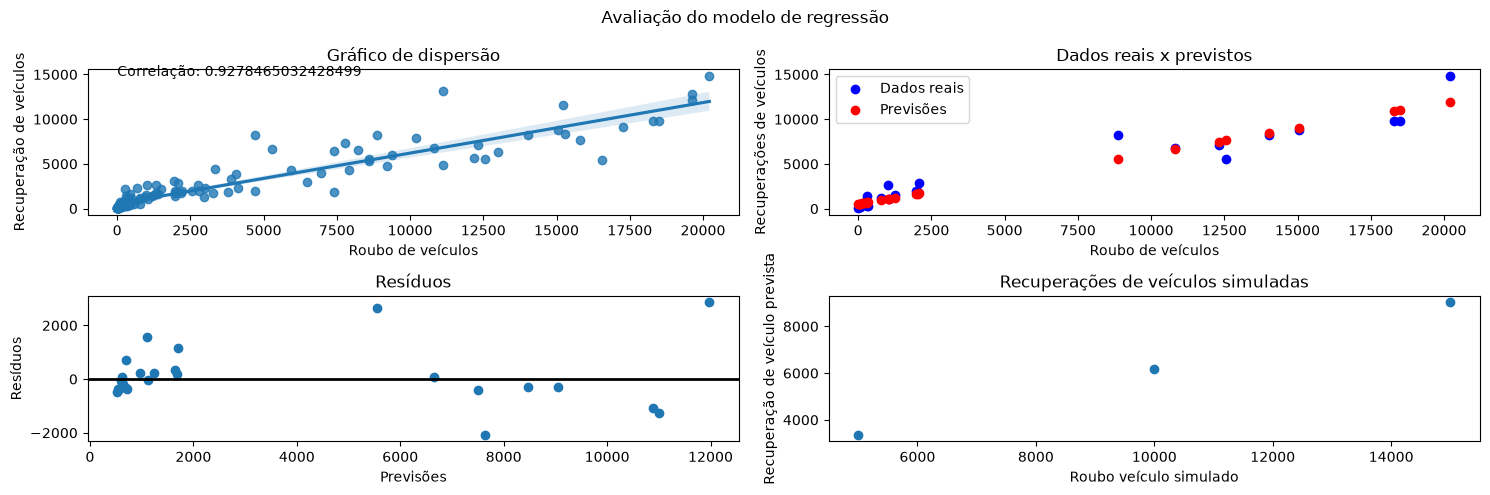

In [9]:
# Avaliando o Modelo
try:
    print('Avaliando o modelo de previsões...')

    plt.subplots(2, 2, figsize=(15, 5))
    plt.suptitle('Avaliação do modelo de regressão')

    # POSIÇÃO 1: Gráfico de dispersão entre os arrays
    # pip install seaborn
    plt.subplot(2, 2, 1)

    import seaborn as sns
    sns.regplot(x=array_roubo_veiculo, y=array_recuperacao_veiculos)
    plt.title('Gráfico de dispersão')
    plt.xlabel('Roubo de veículos')
    plt.ylabel('Recuperação de veículos')

    # Posicionar o texto no início do gráfico
    plt.text(
        min(array_roubo_veiculo),
        max(array_recuperacao_veiculos),
        f'Correlação: {correlacao}', fontsize=10
    )


    # POSIÇÃO 2: Gráfico de dispersão entre os dados reais e previsto
    plt.subplot(2, 2, 2)

    # Testar o modelo preditivo nos dados de X_teste (Padronizados)
    # Saída na escal original dos dados
    y_pred = modelo.predict(X_test)

    # Retornar os dados de teste para escala real
    X_test = scaler.inverse_transform(X_test)

    # Gráfico de dispersão sem a linha de regressão
    plt.scatter(X_test, y_test, color='blue', label='Dados reais')  # Dados reais
    plt.scatter(X_test, y_pred, color = 'red', label='Previsões')  # Previsões

    plt.title('Dados reais x previstos')
    plt.xlabel('Roubo de veículos')
    plt.ylabel('Recuperações de veículos')

    plt.legend()

    # POSIÇÃO 3: Resíduos
    plt.subplot(2, 2, 3)

    # RESÍDUOS:
    # Diferença entre o valor real e o valor previsto: y_test - y_pred.
    # O gráfico ajuda a verificar se o modelo capturou bem os padrões dos dados.
    # O ideal é que os resíduos fiquem dispersos aleatoriamente em torno de 0,
    # sem formar curvas, tendências ou padrões.
    # Padrões nos resíduos indicam que o modelo pode não ser adequado.
    residuos = y_test - y_pred

    # Gráfico de dispersão: previsões no eixo X e resíduos no eixo Y
    plt.scatter(y_pred, residuos)

    # Linha horizontal em 0, referência para os resíduos
    plt.axhline(y=0, color='black', linewidth=2)

    plt.title('Resíduos')
    plt.xlabel('Previsões')
    plt.ylabel('Resíduos')


    # POSIÇÃO 4: dispersão dos valores simulados
    plt.subplot(2, 2, 4)
    
    plt.scatter(array_roubo_veiculo_pred, recup_pred)

    plt.title('Recuperações de veículos simuladas')
    plt.xlabel('Roubo veículo simulado')
    plt.ylabel('Recuperação de veículo prevista')

    plt.tight_layout()
    plt.show()

except Exception as e:
    print("Erro ao avaliar o modelo: ", e)
    exit()

